# Yellow Sigatoka Feature Engineering Review

This notebook reviews existing features and checks whether the stored inputs reproduce the project's synthetic score. No feature values are changed and no model is trained.

## 1. Import Libraries

In [1]:
# Import libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


## 2. Load Data

Load only the existing training and validation splits. The reserved test data is not used.

In [2]:
# Load the datasets
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "datasets" / "yellow_sigatoka"
train_df = pd.read_csv(DATA_DIR / "YS_SIMULATED_train.csv")
validation_df = pd.read_csv(DATA_DIR / "YS_SIMULATED_validation.csv")

FEATURES = [
    "mean_temp_previous_14d_c",
    "wet_hours_previous_14d",
    "consecutive_wetness_hours",
]
TARGET = "risk_score"
print("Training:", train_df.shape, "Validation:", validation_df.shape)


Training: (4200, 32) Validation: (900, 32)


## 3. Existing Features

The three selected features are existing summaries from each generated 336-hour scenario, not new calculations made in this notebook.

In [3]:
# Review the existing features
feature_meaning = pd.DataFrame({
    "Feature": FEATURES,
    "Meaning": [
        "Average air temperature across the 14-day scenario window",
        "Count of estimated wet hours in the 14-day scenario window",
        "Wet-hour streak ending at the scenario's final hour",
    ],
})
display(feature_meaning)
display(train_df[FEATURES + [TARGET]].head())


,Feature,Meaning
0,mean_temp_previous_14d_c,Average air temperature across the 14-day scen...
1,wet_hours_previous_14d,Count of estimated wet hours in the 14-day sce...
2,consecutive_wetness_hours,Wet-hour streak ending at the scenario's final...


,mean_temp_previous_14d_c,wet_hours_previous_14d,consecutive_wetness_hours,risk_score
0,31.675,95,0,15.230
1,20.475,280,11,69.958
2,27.928,199,0,65.076
3,37.280,43,0,0.115
4,22.601,97,1,35.497


## 4. How Features Were Calculated

The builder creates a 336-hour synthetic weather sequence and stores only its final row. It calculates the 14-day average and wet-hour count from that full sequence. The count and average include the final hour; the consecutive wetness count walks backward from that final hour and includes it when wet. The 336 original readings cannot be reconstructed from the saved scenario row.

In [4]:
# Check wetness values and the final-hour timing
rows = []
for split_name, frame in [("Training", train_df), ("Validation", validation_df)]:
    rows.append({
        "Dataset": split_name,
        "Missing/non-finite feature values": int(frame[FEATURES].isna().sum().sum() + (~np.isfinite(frame[FEATURES].to_numpy(dtype=float))).sum()),
        "Wet hours outside 0 to 336": int((~frame["wet_hours_previous_14d"].between(0, 336)).sum()),
        "Consecutive hours outside 0 to 336": int((~frame["consecutive_wetness_hours"].between(0, 336)).sum()),
        "Consecutive hours above total wet hours": int((frame["consecutive_wetness_hours"] > frame["wet_hours_previous_14d"]).sum()),
        "Wet final hour with zero streak": int(((frame["estimated_leaf_wet"] == 1) & (frame["consecutive_wetness_hours"] == 0)).sum()),
        "Dry final hour with positive streak": int(((frame["estimated_leaf_wet"] == 0) & (frame["consecutive_wetness_hours"] > 0)).sum()),
    })
consistency_checks = pd.DataFrame(rows).set_index("Dataset")
display(consistency_checks)


,Missing/non-finite feature values,Wet hours outside 0 to 336,Consecutive hours outside 0 to 336,Consecutive hours above total wet hours,Wet final hour with zero streak,Dry final hour with positive streak
Dataset,,,,,,
Training,0,0,0,0,0,0
Validation,0,0,0,0,0,0


## 5. Check Feature Values

Other weather fields describe the generated scenario or summaries of its simulated 336-hour history. They are not direct inputs to the current score equation. Some overlap with the selected features or may reflect the generator's moisture regimes, so they are not added automatically.

In [5]:
# Review additional available features
other_features = pd.DataFrame([
    ["air_temp_c", "Simulated final-hour temperature", "Not directly; current-hour weather may correlate with the 14-day mean"],
    ["relative_humidity_pct", "Simulated final-hour humidity", "Not directly; generated together with wetness regime"],
    ["wet_hours_previous_24h", "Count of estimated wet hours in the latest 24 hours", "Not directly; subset of the same 336-hour wetness history"],
    ["wet_hours_previous_72h", "Count of estimated wet hours in the latest 72 hours", "Not directly; subset of the same 336-hour wetness history"],
    ["rainfall_previous_14d_mm", "Simulated rainfall sum over the 336-hour history", "Not directly; rainfall contributes to the wetness proxy and co-varies with scenario moisture"],
    ["mean_rh_previous_14d_pct", "Mean simulated relative humidity over the 336-hour history", "Not directly; co-varies with estimated wet hours"],
], columns=["Column", "Type / meaning", "Use in current score formula"])
display(other_features)


,Column,Type / meaning,Use in current score formula
0,air_temp_c,Simulated final-hour temperature,Not directly; current-hour weather may correla...
1,relative_humidity_pct,Simulated final-hour humidity,Not directly; generated together with wetness ...
2,wet_hours_previous_24h,Count of estimated wet hours in the latest 24 ...,Not directly; subset of the same 336-hour wetn...
3,wet_hours_previous_72h,Count of estimated wet hours in the latest 72 ...,Not directly; subset of the same 336-hour wetn...
4,rainfall_previous_14d_mm,Simulated rainfall sum over the 336-hour history,Not directly; rainfall contributes to the wetn...
5,mean_rh_previous_14d_pct,Mean simulated relative humidity over the 336-...,Not directly; co-varies with estimated wet hours


## 6. Feature Relationships

These correlations describe this balanced synthetic dataset. They do not prove causation or biological validity.

,mean_temp_previous_14d_c,wet_hours_previous_14d,consecutive_wetness_hours,risk_score
mean_temp_previous_14d_c,1.000,-0.065,-0.033,-0.481
wet_hours_previous_14d,-0.065,1.000,0.471,0.714
consecutive_wetness_hours,-0.033,0.471,1.000,0.345
risk_score,-0.481,0.714,0.345,1.000


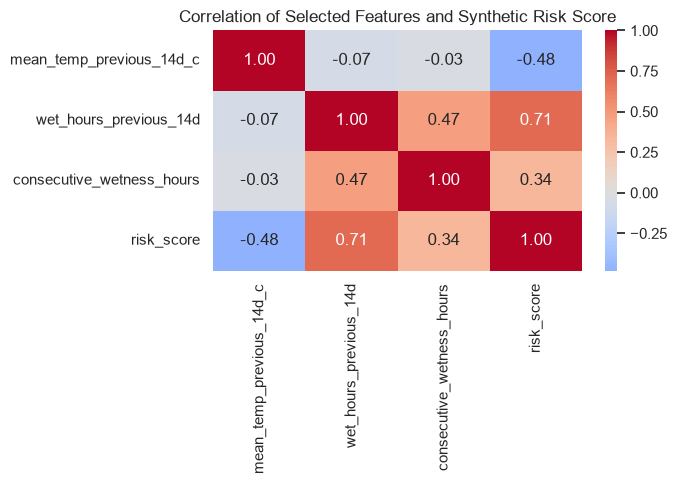

In [6]:
# Review feature relationships
correlation_table = train_df[FEATURES + [TARGET]].corr(numeric_only=True).round(3)
display(correlation_table)

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_table, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation of Selected Features and Synthetic Risk Score")
plt.tight_layout()
plt.show()


## 7. Check for Leakage

Exclude the target, risk category, suitability components, Bonfim flag, identifiers, source and label metadata, and split field. The suitability components are intermediate values used to construct the score. The three selected features are direct inputs to that known formula, which is intentional for a rule-imitation experiment. This does not demonstrate real disease prediction.

In [7]:
# Review target leakage columns
excluded_columns = [
    "risk_level", "temperature_suitability", "wetness_suitability",
    "bonfim_favourable_flag", TARGET, "record_id", "scenario_id",
    "data_origin", "timestamp_utc", "risk_score_type",
    "wetness_estimation_method", "label_method", "split",
]
leakage_review = pd.DataFrame({
    "Column": excluded_columns,
    "Present in data": [column in train_df.columns for column in excluded_columns],
    "Decision": ["Exclude from model inputs" for _ in excluded_columns],
})
display(leakage_review)
print("Other inspected weather fields are not calculated from risk_score in the builder.")
print("Scenario rows were selected/balanced using score-derived categories; this is part of the synthetic dataset design.")


,Column,Present in data,Decision
0,risk_level,True,Exclude from model inputs
1,temperature_suitability,True,Exclude from model inputs
2,wetness_suitability,True,Exclude from model inputs
3,bonfim_favourable_flag,True,Exclude from model inputs
4,risk_score,True,Exclude from model inputs
5,record_id,True,Exclude from model inputs
6,scenario_id,True,Exclude from model inputs
7,data_origin,True,Exclude from model inputs
8,timestamp_utc,True,Exclude from model inputs
9,risk_score_type,True,Exclude from model inputs


Other inspected weather fields are not calculated from risk_score in the builder.
Scenario rows were selected/balanced using score-derived categories; this is part of the synthetic dataset design.


## 8. Selected Model Features

Keep the three approved inputs in their current order. The scoring formula is project-defined, not a published infection-probability equation. Its deterministic calculation can be used as a baseline when later comparing machine-learning models.

,MAE,Maximum absolute error,Rows within 0.01 score points,Rows
Dataset,,,,
Training,0.00106,0.004,4200,4200
Validation,0.00102,0.004,900,900


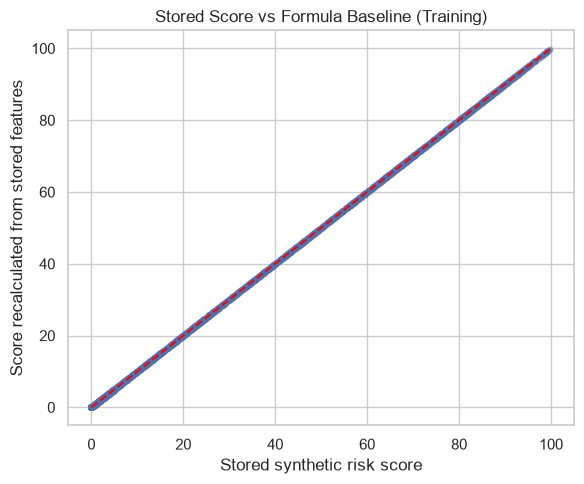

Selected model features: ['mean_temp_previous_14d_c', 'wet_hours_previous_14d', 'consecutive_wetness_hours']
Target: risk_score


In [8]:
# Check the scoring formula against stored scores
T14 = train_df[FEATURES[0]].to_numpy(dtype=float)
LW14 = train_df[FEATURES[1]].to_numpy(dtype=float)
C = train_df[FEATURES[2]].to_numpy(dtype=float)

# Apply the documented project heuristic
TempSuit = np.where(T14 <= 25, (T14 - 8) / 17, (37.5 - T14) / 12.5)
TempSuit = np.clip(TempSuit, 0, 1)
WetAnchor = np.where((T14 > 21) & (T14 <= 25), 130, 160)
WetSuit = np.clip((LW14 - 30) / (WetAnchor + 45 - 30), 0, 1)
Continuity = np.clip(C / 18, 0, 1)
formula_score = np.round(np.clip(100 * TempSuit * (0.88 * WetSuit + 0.12 * Continuity), 0, 100), 3)

formula_results = []
for split_name, frame, recalculated in [
    ("Training", train_df, formula_score),
    ("Validation", validation_df, np.round(np.clip(
        100 * np.clip(np.where(validation_df[FEATURES[0]].to_numpy(dtype=float) <= 25,
                               (validation_df[FEATURES[0]].to_numpy(dtype=float) - 8) / 17,
                               (37.5 - validation_df[FEATURES[0]].to_numpy(dtype=float)) / 12.5), 0, 1)
        * (0.88 * np.clip((validation_df[FEATURES[1]].to_numpy(dtype=float) - 30) /
                          (np.where((validation_df[FEATURES[0]].to_numpy(dtype=float) > 21) &
                                    (validation_df[FEATURES[0]].to_numpy(dtype=float) <= 25), 130, 160) + 45 - 30), 0, 1)
           + 0.12 * np.clip(validation_df[FEATURES[2]].to_numpy(dtype=float) / 18, 0, 1)), 0, 100), 3)),
]:
    absolute_error = np.abs(recalculated - frame[TARGET].to_numpy(dtype=float))
    formula_results.append({
        "Dataset": split_name,
        "MAE": absolute_error.mean(),
        "Maximum absolute error": absolute_error.max(),
        "Rows within 0.01 score points": int((absolute_error <= 0.01).sum()),
        "Rows": len(frame),
    })
formula_summary = pd.DataFrame(formula_results).set_index("Dataset").round(5)
display(formula_summary)

plt.figure(figsize=(6, 5))
plt.scatter(train_df[TARGET], formula_score, alpha=0.25, s=14)
plt.plot([0, 100], [0, 100], color="red", linestyle="--")
plt.xlabel("Stored synthetic risk score")
plt.ylabel("Score recalculated from stored features")
plt.title("Stored Score vs Formula Baseline (Training)")
plt.tight_layout()
plt.show()

# Confirm the selected input order
selected_features = FEATURES.copy()
print("Selected model features:", selected_features)
print("Target:", TARGET)


## 9. Feature Engineering Summary

The selected inputs are consistent with the generator and reproduce the stored scores up to rounding in the saved feature values. For a future live backend, calculate features from the latest 336 chronological hourly readings available at prediction time. Require a complete, regular hourly window or apply an explicit documented missing-data policy; do not treat missing readings as dry. Regularize or reject irregular timestamps, and withhold a prediction when history is insufficient. Consecutive wetness increments on wet readings and resets to zero on a dry reading. No live sensor connection is assumed.

In [9]:
# Save the feature engineering report
from IPython.display import Markdown, display

report_lines = [
    "# Yellow Sigatoka Feature Engineering Report",
    "",
    "## Existing engineered features",
    "- `mean_temp_previous_14d_c`: average temperature over the 336-hour simulated window.",
    "- `wet_hours_previous_14d`: count of estimated wet readings over the same window.",
    "- `consecutive_wetness_hours`: wet streak ending at the final hour, including that hour when wet.",
    "- The generator calculates these from a full 336-hour scenario but saves only its final row. The original hourly readings cannot be recovered from the scenario CSVs.",
    "",
    "## Feature consistency",
    f"- All selected features are present, finite, and non-missing in training ({len(train_df):,}) and validation ({len(validation_df):,}).",
    f"- Wet-hours and consecutive-hours bounds passed; streaks above total wet hours: training {int(consistency_checks.loc['Training', 'Consecutive hours above total wet hours'])}, validation {int(consistency_checks.loc['Validation', 'Consecutive hours above total wet hours'])}.",
    f"- Wet final-hour/streak mismatches: training wet-with-zero {int(consistency_checks.loc['Training', 'Wet final hour with zero streak'])}, dry-with-positive {int(consistency_checks.loc['Training', 'Dry final hour with positive streak'])}; validation wet-with-zero {int(consistency_checks.loc['Validation', 'Wet final hour with zero streak'])}, dry-with-positive {int(consistency_checks.loc['Validation', 'Dry final hour with positive streak'])}.",
    "",
    "## Score formula and leakage review",
    "The builder's project heuristic uses temperature suitability, wetness suitability, and continuity: `100 x TempSuit x (0.88 x WetSuit + 0.12 x Continuity)`. Wetness anchor is 130 hours when 21 < T14 <= 25 C and otherwise 160 hours. This is an engineering rule, not a published infection-probability equation.",
    f"- Formula reproduction from stored rounded features: training MAE {formula_summary.loc['Training', 'MAE']:.5f}, maximum absolute error {formula_summary.loc['Training', 'Maximum absolute error']:.5f}; validation MAE {formula_summary.loc['Validation', 'MAE']:.5f}, maximum absolute error {formula_summary.loc['Validation', 'Maximum absolute error']:.5f}.",
    "- All score differences are within 0.01 points and are consistent with rounding the stored input features. The formula can be a deterministic baseline for later model comparisons.",
    "- Exclude risk score, risk level, suitability components, Bonfim flag, IDs, source/label metadata, and split metadata. Suitability components are intermediate target calculations. The selected three features directly define the target, so a model will imitate the rule, not establish real disease prediction.",
    "- The builder does not calculate additional weather columns from the score. It does balance/select scenarios using score-derived categories; this is part of the synthetic data design.",
    "",
    "## Selected inputs and additional features",
    "Keep `mean_temp_previous_14d_c`, `wet_hours_previous_14d`, and `consecutive_wetness_hours` as the approved inputs. Air temperature, humidity, shorter wet-hour counts, 14-day rainfall, and 14-day mean humidity are available but are not direct inputs to the current score formula. They are simulated/derived from the same generated weather windows and should only be considered later with a clear research reason and leakage review.",
    "With actual chronological measurements, possible future candidates include measured temperature, humidity, rainfall, direct leaf-wetness sensor readings, and carefully defined shorter rolling summaries. No extra feature is added here.",
    "",
    "## Future backend requirements and limitations",
    "At prediction time, use only current and past readings. Calculate the average temperature and wet-hour count over the latest 336 hourly readings, and count the consecutive wet run ending at the latest reading. Require sufficient history and a documented policy for missing readings; do not silently treat missing values as dry. Regularize or reject irregular timestamps before calculating hour-based windows.",
    "The scenario CSVs contain one final row per synthetic window, not recoverable source-hour sequences. They are not proof of connected IoT sensors. Train/validation scenario IDs are distinct, but source NASA windows may overlap across scenarios. The score is synthetic environmental suitability, not observed disease incidence.",
]
report_path = PROJECT_ROOT / "reports" / "yellow_sigatoka" / "feature_engineering" / "Feature_Engineering_Report.md"
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("Saved report:", report_path)
display(Markdown("Feature review complete. No source values were changed and no model was trained."))


Saved report: C:\Users\HP\Desktop\ML training\reports\yellow_sigatoka\feature_engineering\Feature_Engineering_Report.md


Feature review complete. No source values were changed and no model was trained.